# FIFA World Cup 2026 — Linear Regression 2.1 and 2.2 (analysis notebook)
This notebook walks through the whole analysis using the modules in `src/`:

| Step | Module |
|---|---|
| Build the datasets (8 pre-match variables per model) | `features.py` |
| Exploratory data analysis | this notebook + `figures.py` |
| Feature-engineering experiments | `experiments.py` |
| Competing algorithms, nested CV and knockout hold-out | `models.py`, `evaluation.py` |
| Final-model inference and diagnostics | `final_model.py` |

The slow steps (experiments and the algorithm comparison, about 20 minutes) are loaded from `results/` by default. Set `RERUN = True` to recompute them.

In [1]:
import sys, warnings; sys.path.insert(0, "../src"); warnings.filterwarnings("ignore")
import pandas as pd
from IPython.display import Image, display
import features, experiments, models, final_model, figures
from features import FINAL, X21, X22, SHARED, build
RERUN = False
pd.set_option("display.precision", 3); pd.set_option("display.width", 200)

## 1. Datasets

In [2]:
d21, d22 = build(FINAL, save=True)
print("LR 2.1:", d21.shape, "| LR 2.2:", d22.shape)
assert len(X21) == 8 and len(X22) == 8 and len(SHARED) <= 4
display(pd.DataFrame(SHARED, index=["LR 2.1", "LR 2.2"]).T.rename_axis("Shared variable"))
display(d21[["match_id", "stage", "team_a", "team_b"] + X21 + ["goal_difference"]].head())
display(d22[["row_id", "match_id", "team", "opponent"] + X22 + ["goals_scored"]].head())

LR 2.1: (104, 13) | LR 2.2: (208, 14)


,LR 2.1,LR 2.2
Shared variable,,
FIFA ranking,rank_diff,team_rank
Host nation,host_diff,team_is_host
Rest days,rest_diff,team_rest
Prior goals scored,prior_goals_scored_diff,team_prior_goals_scored


,match_id,stage,team_a,team_b,rank_diff,host_diff,rest_diff,prior_goals_scored_diff,prior_goals_conceded_diff,prior_points_per_game_diff,prior_clean_sheet_rate_diff,elite_confederation_diff,goal_difference
0,1,Group A,Mexico,South Africa,-1.455,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2
1,2,Group A,Korea Republic,Czechia,-0.470,0.0,0.0,0.0,0.0,0.0,0.0,-1.0,1
2,3,Group B,Canada,Bosnia and Herzegovina,-0.758,1.0,0.0,0.0,0.0,0.0,0.0,-1.0,0
3,4,Group D,USA,Paraguay,-0.880,1.0,0.0,0.0,0.0,0.0,0.0,-1.0,3
4,5,Group B,Qatar,Switzerland,1.081,0.0,0.0,0.0,0.0,0.0,0.0,-1.0,0


,row_id,match_id,team,opponent,team_rank,team_is_host,team_rest,team_prior_goals_scored,opp_rank,opp_goals_conceded_prev_match,is_knockout,matchday,goals_scored
0,1,1,Mexico,South Africa,2.639,1.0,5.275,1.344,4.094,1.344,0.0,1.0,2
1,2,1,South Africa,Mexico,4.094,0.0,5.275,1.344,2.639,1.344,0.0,1.0,0
2,3,2,Czechia,Korea Republic,3.689,0.0,5.275,1.344,3.219,1.344,0.0,1.0,1
3,4,2,Korea Republic,Czechia,3.219,0.0,5.275,1.344,3.689,1.344,0.0,1.0,2
4,5,3,Bosnia and Herzegovina,Canada,4.159,0.0,5.275,1.250,3.401,1.250,0.0,1.0,1


## 2. Exploratory data analysis

,count,mean,std,min,25%,50%,75%,max
rank_diff,104.0,-0.382,1.584,-4.205,-1.416,-0.431,0.776,4.143
host_diff,104.0,0.067,0.376,-1.000,0.000,0.000,0.000,1.000
rest_diff,104.0,0.058,0.554,-1.000,0.000,0.000,0.000,1.000
prior_goals_scored_diff,104.0,0.013,0.420,-1.500,-0.167,0.000,0.213,1.200
prior_goals_conceded_diff,104.0,-0.059,0.377,-1.200,-0.206,0.000,0.111,1.000
prior_points_per_game_diff,104.0,0.029,0.336,-1.000,0.000,0.000,0.186,0.857
prior_clean_sheet_rate_diff,104.0,0.014,0.153,-0.333,0.000,0.000,0.028,0.444
elite_confederation_diff,104.0,0.154,0.747,-1.000,0.000,0.000,1.000,1.000
goal_difference,104.0,0.481,2.024,-4.000,-1.000,0.000,2.000,6.000


,count,mean,std,min,25%,50%,75%,max
team_rank,208.0,2.843,1.144,0.000,2.168,3.113,3.714,4.443
team_is_host,208.0,0.072,0.259,0.000,0.000,0.000,0.000,1.000
team_rest,208.0,5.184,0.760,3.000,5.000,5.275,6.000,6.000
team_prior_goals_scored,208.0,1.560,0.323,0.979,1.344,1.483,1.738,2.600
opp_rank,208.0,2.843,1.144,0.000,2.168,3.113,3.714,4.443
opp_goals_conceded_prev_match,208.0,1.432,0.243,1.160,1.200,1.400,1.550,2.600
is_knockout,208.0,0.308,0.463,0.000,0.000,0.000,1.000,1.000
matchday,208.0,2.904,1.660,1.000,2.000,3.000,4.000,8.000
goals_scored,208.0,1.481,1.393,0.000,0.000,1.000,2.000,7.000


Draws: 23% | mean |GD| group 1.65 vs knockout 1.34
Goals per team: mean 1.48, variance 1.94
Rest equal for both teams: 69% of matches
Correlation with target (LR 2.1):


,r
rank_diff,-0.629
prior_goals_conceded_diff,-0.326
rest_diff,0.088
host_diff,0.123
prior_goals_scored_diff,0.157
prior_clean_sheet_rate_diff,0.206
prior_points_per_game_diff,0.310
elite_confederation_diff,0.316


Correlation with target (LR 2.2):


,r
team_rank,-0.369
team_rest,-0.091
is_knockout,-0.013
matchday,0.026
team_prior_goals_scored,0.082
team_is_host,0.104
opp_goals_conceded_prev_match,0.128
opp_rank,0.319


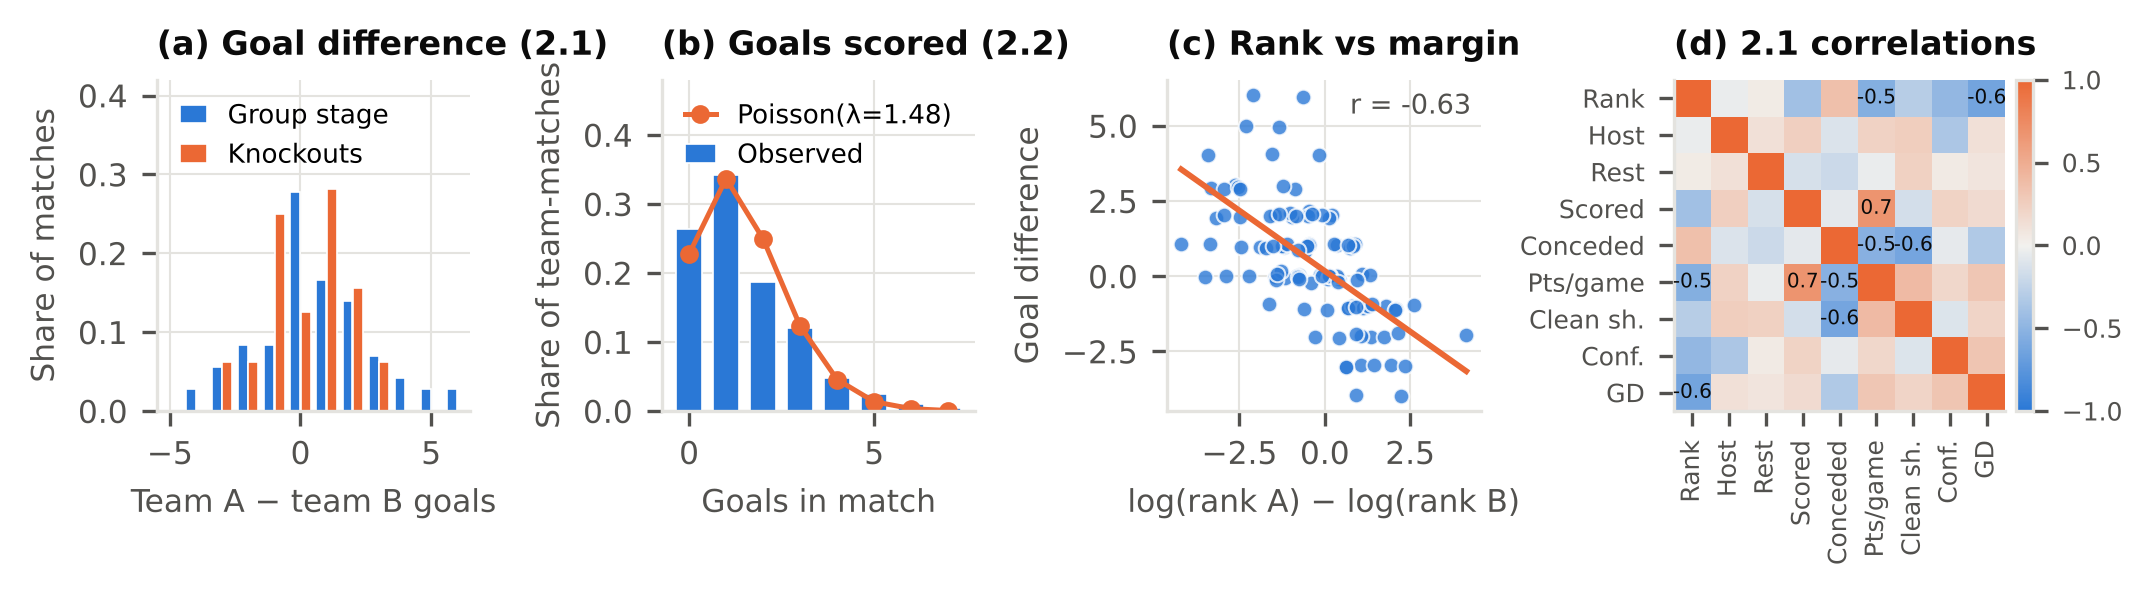

In [3]:
display(d21[X21 + ["goal_difference"]].describe().T)
display(d22[X22 + ["goals_scored"]].describe().T)
ko = ~d21.stage.str.startswith("Group")
print(f"Draws: {(d21.goal_difference == 0).mean():.0%} | mean |GD| group {d21.goal_difference[~ko].abs().mean():.2f} vs knockout {d21.goal_difference[ko].abs().mean():.2f}")
print(f"Goals per team: mean {d22.goals_scored.mean():.2f}, variance {d22.goals_scored.var():.2f}")
print(f"Rest equal for both teams: {(d21.rest_diff == 0).mean():.0%} of matches")
print("Correlation with target (LR 2.1):"); display(d21[X21].corrwith(d21.goal_difference).sort_values().to_frame("r"))
print("Correlation with target (LR 2.2):"); display(d22[X22].corrwith(d22.goals_scored).sort_values().to_frame("r"))
figures.FIG.mkdir(exist_ok=True); figures.fig_eda(); display(Image(str(figures.FIG / "fig1_eda.png")))

## 3. Feature-engineering experiments (16 configurations, OLS, repeated CV)

In [4]:
fe = experiments.run() if RERUN else pd.read_csv(features.ROOT / "results" / "feature_engineering_experiments.csv")
fe.drop(columns=[c for c in fe if c.startswith("cfg_")])

,config,2.1 CV RMSE,2.1 CV R2,2.1 hold-out RMSE,2.2 CV RMSE,2.2 CV R2,2.2 hold-out RMSE,mean CV RMSE rank
0,"rank=log, form=shrunk k=4, rest=sign",1.619,0.265,1.869,1.251,0.159,1.132,1.5
1,"rank=log, form=shrunk k=2, rest=sign",1.630,0.255,1.863,1.251,0.159,1.127,3.0
2,"rank=log, form=shrunk k=4, rest=raw",1.612,0.271,1.908,1.260,0.149,1.137,3.5
3,"rank=log, form=shrunk k=2, rest=raw",1.622,0.261,1.903,1.259,0.148,1.132,4.0
4,"rank=log, form=shrunk k=1, rest=sign",1.642,0.243,1.861,1.252,0.158,1.123,4.5
5,"rank=log, form=shrunk k=1, rest=raw",1.634,0.250,1.901,1.260,0.148,1.129,6.0
6,"rank=log, form=mean-fill, rest=sign",1.671,0.215,1.863,1.253,0.156,1.130,6.0
7,"rank=log, form=mean-fill, rest=raw",1.662,0.223,1.904,1.261,0.146,1.134,7.5
8,"rank=raw, form=shrunk k=4, rest=sign",1.686,0.202,2.288,1.270,0.130,1.158,11.5
9,"rank=raw, form=shrunk k=1, rest=sign",1.696,0.190,2.190,1.270,0.130,1.146,11.5


## 4. Competing algorithms (nested CV + knockout hold-out)

In [5]:
for t in ["21", "22"]:
    res = models.compare(t[0] + "." + t[1]) if RERUN else pd.read_csv(features.ROOT / "results" / f"model_comparison_{t}.csv")
    print(f"LR {t[0]}.{t[1]}"); display(res)

LR 2.1


,Model,CV RMSE,CV RMSE sd,CV MAE,CV R2,Hold-out RMSE,Hold-out MAE,Hold-out R2,CV result acc,Hold-out result acc,t vs OLS,p vs OLS,% folds better than OLS
0,Mean baseline,2.007,0.351,1.592,-0.070,1.621,1.344,-0.058,0.299,0.500,-2.812,0.006,11.0
1,Rank-only OLS,1.582,0.265,1.238,0.311,1.393,1.083,0.218,0.619,0.719,0.481,0.631,48.0
2,OLS,1.619,0.249,1.253,0.265,1.869,1.417,-0.406,0.615,0.625,NaN,NaN,0.0
3,Ridge,1.622,0.257,1.257,0.275,1.886,1.419,-0.432,0.615,0.594,-0.092,0.927,55.0
4,Lasso,1.653,0.266,1.284,0.256,1.725,1.280,-0.198,0.565,0.625,-0.552,0.582,43.0
5,Elastic Net,1.664,0.257,1.291,0.242,1.822,1.347,-0.336,0.566,0.562,-0.782,0.436,44.0
6,Huber (robust),1.634,0.251,1.281,0.262,1.909,1.443,-0.468,0.603,0.594,-0.423,0.673,53.0
7,Random forest,1.625,0.245,1.299,0.264,1.497,1.185,0.097,0.642,0.688,-0.071,0.943,49.0


LR 2.2


,Model,CV RMSE,CV RMSE sd,CV MAE,CV R2,Hold-out RMSE,Hold-out MAE,Hold-out R2,t vs OLS,p vs OLS,% folds better than OLS
0,Mean baseline,1.386,0.167,1.115,-0.023,1.212,0.984,-0.001,-3.182,0.002,7.0
1,Rank-only OLS,1.224,0.167,0.909,0.200,1.134,0.819,0.123,1.098,0.275,69.0
2,OLS,1.251,0.162,0.944,0.159,1.132,0.833,0.127,NaN,NaN,0.0
3,Ridge,1.242,0.165,0.938,0.175,1.109,0.824,0.162,0.927,0.356,69.0
4,Lasso,1.247,0.165,0.938,0.168,1.107,0.819,0.165,0.281,0.779,58.0
5,Elastic Net,1.247,0.164,0.939,0.169,1.100,0.818,0.175,0.310,0.757,59.0
6,Huber (robust),1.244,0.163,0.935,0.172,1.099,0.813,0.176,0.638,0.525,65.0
7,Random forest,1.270,0.160,0.972,0.137,1.117,0.893,0.149,-0.624,0.534,36.0
8,Poisson GLM,1.251,0.178,0.948,0.166,1.153,0.846,0.094,0.011,0.991,42.0


## 5. Final models — inference, assumptions and feature importance

In [6]:
o = final_model.run()
print(o["r21"].summary()); print(o["r22"].summary())

                            OLS Regression Results                            
Dep. Variable:        goal_difference   R-squared:                       0.460
Model:                            OLS   Adj. R-squared:                  0.415
Method:                 Least Squares   F-statistic:                     10.13
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           4.03e-10
Time:                        13:34:37   Log-Likelihood:                -188.33
No. Observations:                 104   AIC:                             394.7
Df Residuals:                      95   BIC:                             418.5
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const             

In [7]:
display(o["c21"]); display(o["c22"]); display(o["diag"])
print("Drop-column importance (rise in CV RMSE when removed)"); display(o["i21"]); display(o["i22"])

,coef,std_err,p_value,ci_low,ci_high,std_coef,std_ci_low,std_ci_high
const,0.028,0.164,8.644e-01,-0.297,0.353,NaN,NaN,NaN
rank_diff,-0.833,0.135,1.695e-08,-1.101,-0.565,-0.652,-0.862,-0.442
host_diff,1.104,0.497,2.882e-02,0.117,2.091,0.205,0.022,0.388
rest_diff,0.259,0.296,3.844e-01,-0.329,0.847,0.071,-0.090,0.232
prior_goals_scored_diff,-1.177,0.681,8.732e-02,-2.529,0.176,-0.244,-0.525,0.036
prior_goals_conceded_diff,-0.886,0.581,1.306e-01,-2.039,0.267,-0.165,-0.380,0.050
prior_points_per_game_diff,0.334,0.925,7.190e-01,-1.503,2.170,0.055,-0.250,0.360
prior_clean_sheet_rate_diff,-2.712,1.614,9.622e-02,-5.916,0.492,-0.205,-0.447,0.037
elite_confederation_diff,0.243,0.266,3.643e-01,-0.286,0.772,0.090,-0.106,0.285


,coef,std_err,p_value,ci_low,ci_high,std_coef,std_ci_low,std_ci_high,p_value_clustered,poisson_coef,poisson_p
const,3.068,1.118,6.617e-03,0.863,5.272,NaN,NaN,NaN,1.107e-02,1.075,1.554e-01
team_rank,-0.506,0.091,9.463e-08,-0.686,-0.326,-0.415,-0.563,-0.268,4.335e-08,-0.309,4.276e-08
team_is_host,0.699,0.340,4.143e-02,0.027,1.370,0.130,0.005,0.255,6.795e-02,0.477,2.003e-02
team_rest,-0.239,0.127,6.044e-02,-0.489,0.011,-0.131,-0.267,0.006,6.363e-02,-0.169,4.451e-02
team_prior_goals_scored,-0.479,0.324,1.414e-01,-1.119,0.161,-0.111,-0.259,0.037,1.161e-01,-0.290,1.959e-01
opp_rank,0.340,0.087,1.302e-04,0.168,0.512,0.279,0.138,0.420,5.306e-05,0.284,2.466e-05
opp_goals_conceded_prev_match,0.560,0.373,1.342e-01,-0.174,1.295,0.098,-0.030,0.226,2.157e-01,0.333,1.624e-01
is_knockout,-0.227,0.323,4.823e-01,-0.864,0.410,-0.075,-0.287,0.136,5.090e-01,-0.150,4.976e-01
matchday,0.031,0.099,7.540e-01,-0.165,0.227,0.037,-0.196,0.270,8.060e-01,0.044,5.208e-01


,2.1 OLS,2.2 OLS
n,1.040e+02,2.080e+02
R2,4.603e-01,2.730e-01
Adj R2,4.148e-01,2.437e-01
F p-value,4.026e-10,6.437e-11
AIC,3.947e+02,6.790e+02
Shapiro-Wilk p,7.590e-02,1.205e-05
Breusch-Pagan p,3.715e-01,4.936e-02
Durbin-Watson,1.956e+00,1.895e+00
Max VIF,4.155e+00,3.823e+00
VIF rank_diff,1.968e+00,NaN


Drop-column importance (rise in CV RMSE when removed)


,variable,CV RMSE without it,RMSE increase
0,rank_diff,1.894,0.275
3,prior_goals_scored_diff,1.641,0.022
1,host_diff,1.631,0.012
6,prior_clean_sheet_rate_diff,1.630,0.011
4,prior_goals_conceded_diff,1.622,0.003
7,elite_confederation_diff,1.609,-0.010
5,prior_points_per_game_diff,1.608,-0.011
2,rest_diff,1.604,-0.015


,variable,CV RMSE without it,RMSE increase
0,team_rank,1.334,8.265e-02
4,opp_rank,1.291,4.017e-02
1,team_is_host,1.254,2.380e-03
3,team_prior_goals_scored,1.253,2.102e-03
2,team_rest,1.250,-7.889e-04
5,opp_goals_conceded_prev_match,1.248,-2.996e-03
6,is_knockout,1.244,-7.649e-03
7,matchday,1.240,-1.164e-02


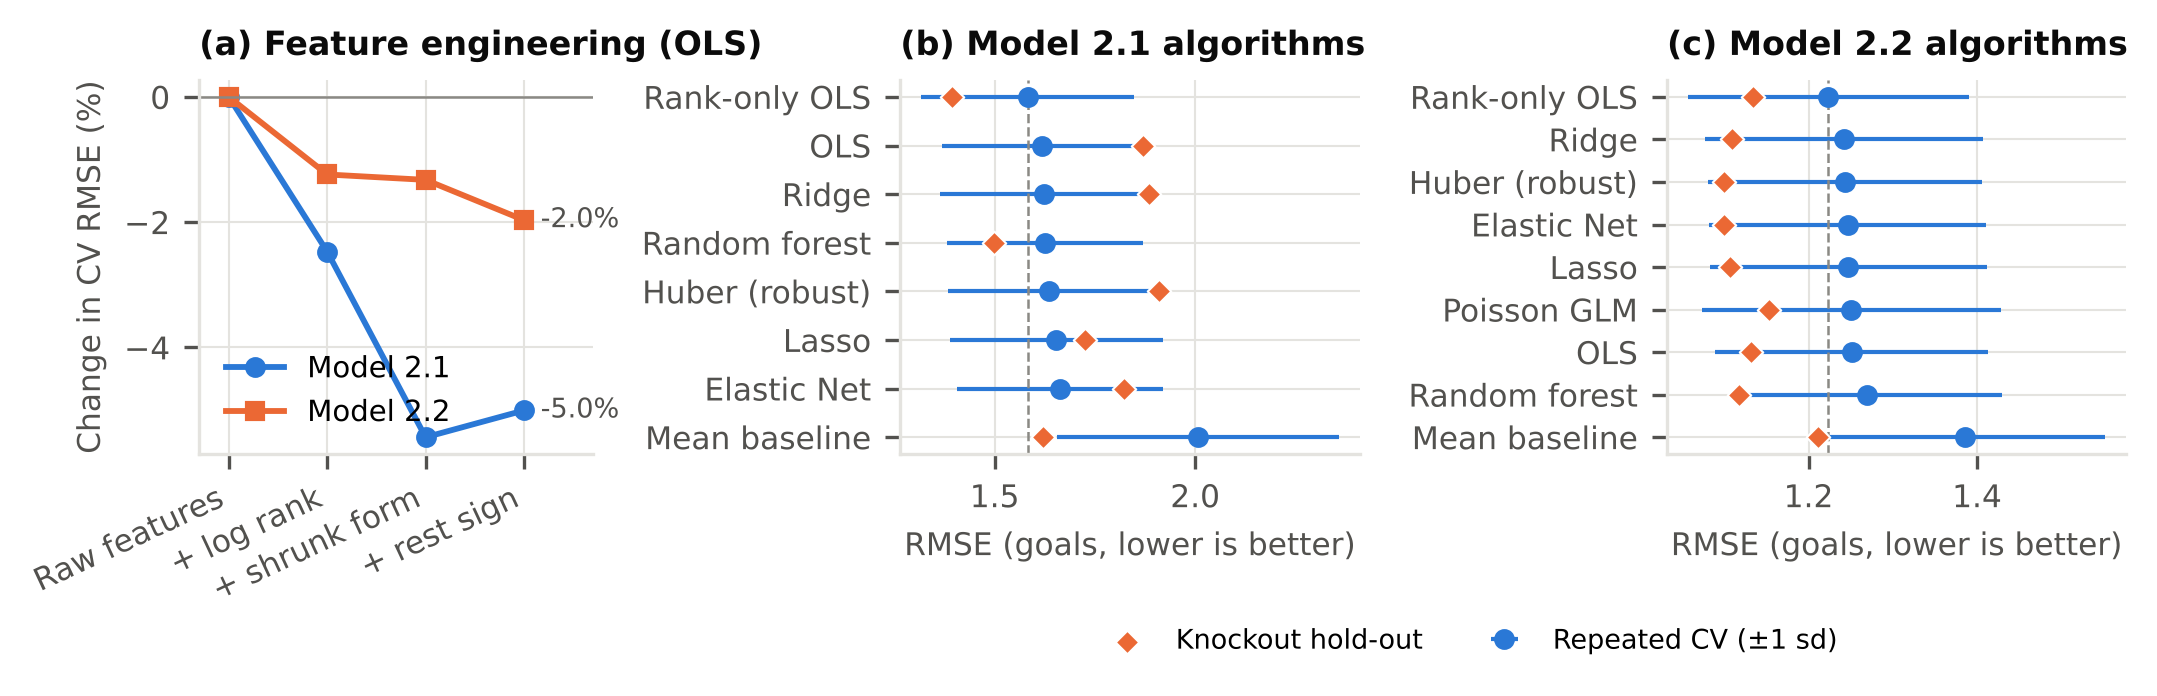

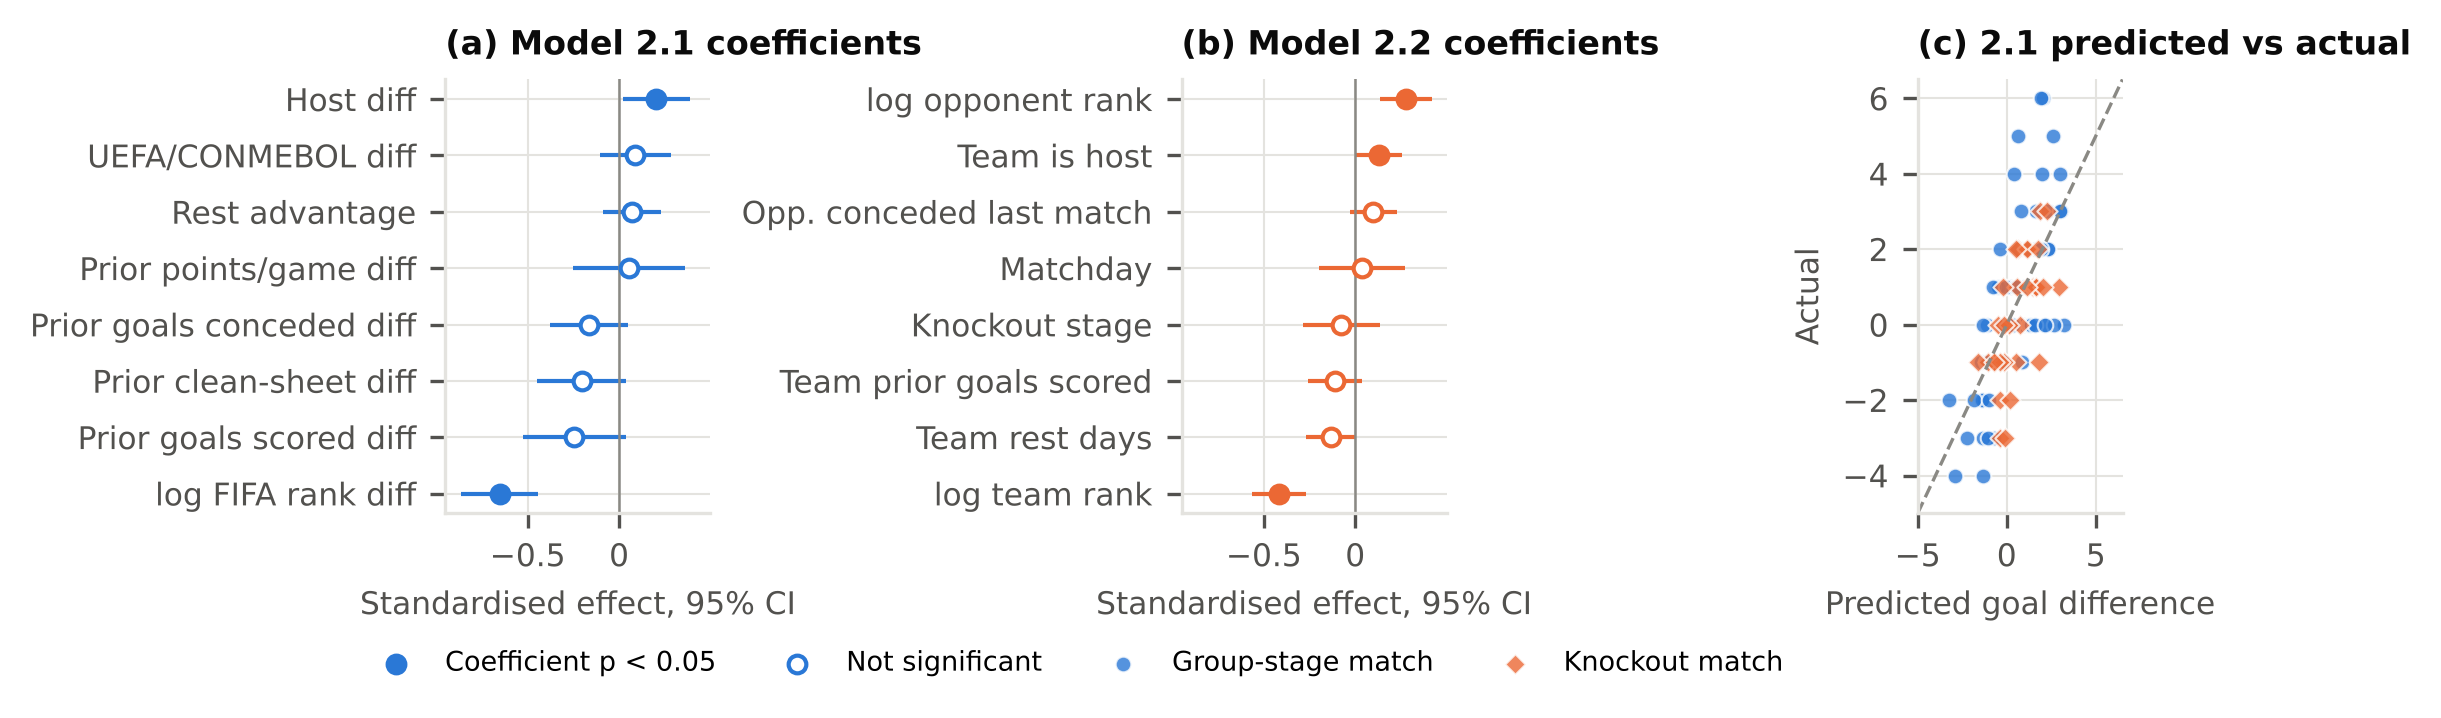

In [8]:
figures.fig_models(); figures.fig_final()
display(Image(str(figures.FIG / "fig2_models.png"))); display(Image(str(figures.FIG / "fig3_final.png")))

## 6. Conclusions
* **LR 2.1:** the 8-variable OLS model explains 46% of the variance (adjusted R² 0.41). The significant predictors are FIFA ranking (log) and host advantage. For prediction, the ranking-only model is best: CV RMSE 1.58, knockout hold-out RMSE 1.39, and the correct result in 72% of knockout matches.
* **LR 2.2:** OLS explains 27% of the variance (adjusted R² 0.24). Own ranking and opponent ranking are the key predictors. Ridge is the best 8-variable model for prediction, and a Poisson GLM is recommended for non-negative predictions of goal counts.